In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log

question_data = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
paragraphs = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

In [192]:
# Display Open Router usage log: (for now count starts t 2.9$)
display_usage_log()

Open Router all time usage cost: 11.800$
Daily usage:
 - 2026-04-09: 0.023$
 - 2026-04-10: 0.061$
 - 2026-04-11: 1.092$
 - 2026-04-12: 0.092$
 - 2026-04-13: 1.658$
 - 2026-04-14: 0.027$
 - 2026-04-15: 2.356$
 - 2026-04-18: 6.491$


In [200]:
from knowledge_maze.create_dataset.create_context.verifier import UnifiedValidationSweep

q_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
p_dataset=load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))

models_to_sweep = [
    # "google/gemini-3-flash-preview",
    # "google/gemini-3.1-flash-lite-preview",
    # "x-ai/grok-4.20"
    # "x-ai/grok-4.1-fast",
    # "openai/gpt-5.1-codex-mini",
    # "openai/gpt-5.4-mini",
    # "meta-llama/llama-4-maverick",
    # "qwen/qwen3.5-flash-02-23",
    # "mistralai/mistral-medium-3.1",
    # "anthropic/claude-haiku-4.5",
    # "z-ai/glm-4.7-flash",
    # "moonshotai/kimi-k2.5",
]

# Instantiate with the judge model
sweep = UnifiedValidationSweep(
    model_list=models_to_sweep, 
    judge_model="google/gemini-3.1-flash-lite-preview"
)

# Run the sweep:
results_df = await sweep.run_sweep(q_dataset, p_dataset, sample_limit=67)

🚀 Starting CONSISTENCY sweep: 1 models, 67 samples.

🔍 Evaluating Consistency: google/gemini-3.1-flash-lite-preview...


Inferencing google/gemini-3.1-flash-lite-preview:   0%|          | 0/402 [00:00<?, ?it/s]

CancelledError: 

# Models ablation study:

In [42]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

model_evaluation_results = {}

eval_models = [
    "google/gemini-3-flash-preview",
    "mistralai/mistral-small-3.2-24b-instruct",
    "openai/gpt-4o-mini",
    "deepseek/deepseek-v3.2"
]

for model in eval_models:
    
    # Initialize the class, passing in the desired model
    evaluator = KnowledgeMazeEvaluator(
        repo_path=REPO_PATH, 
        model_name=model,
        similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
    )

    # Run the async pipeline
    results = await evaluator.run_evaluation()

    # Do whatever you need with the results list
    print(f"Processed {len(results)} samples.")

    model_evaluation_results[model] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: openai/gpt-4o-mini...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: deepseek/deepseek-v3.2...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output": "6"\n}\n```', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output"...ga, is 372973."\n}\n```', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output": "6"\n}\n```', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
API Error: 1 validation error for StringResponse
  Invalid JSON: expected value at line 1 column 1 [type=json_invalid, input_value='```json\n{\n    "Output"...on, and Jorhat"\n}

In [43]:
model_evaluation_results.keys()

dict_keys(['google/gemini-3-flash-preview', 'mistralai/mistral-small-3.2-24b-instruct', 'openai/gpt-4o-mini', 'deepseek/deepseek-v3.2'])

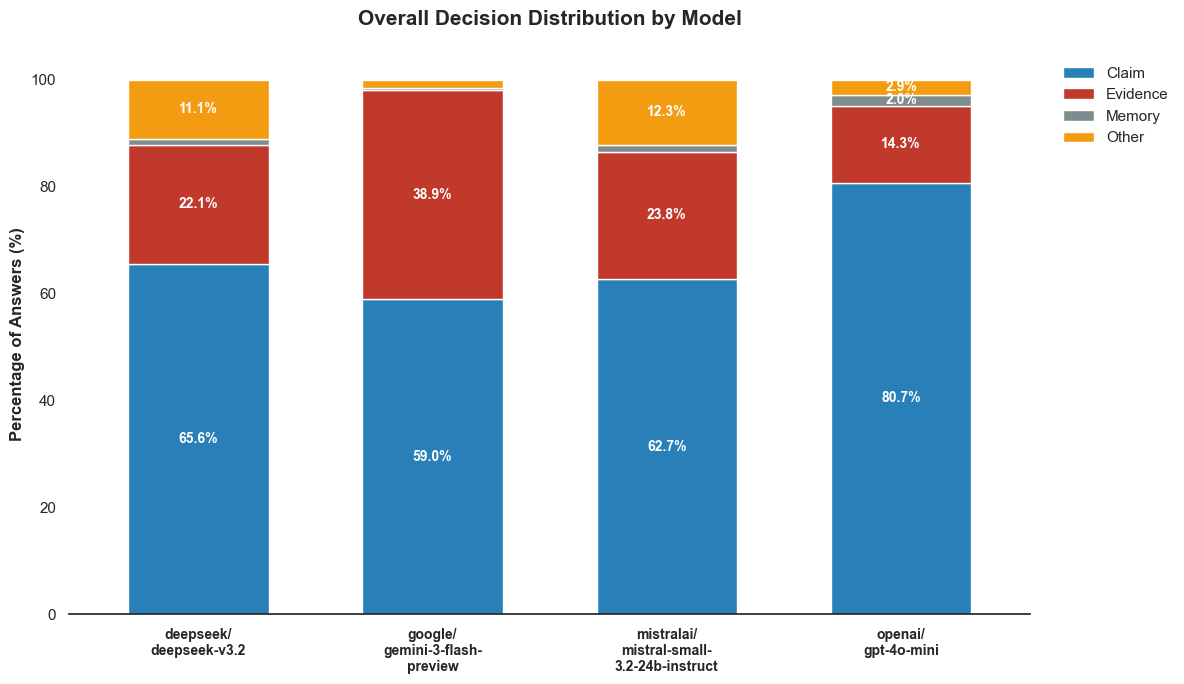

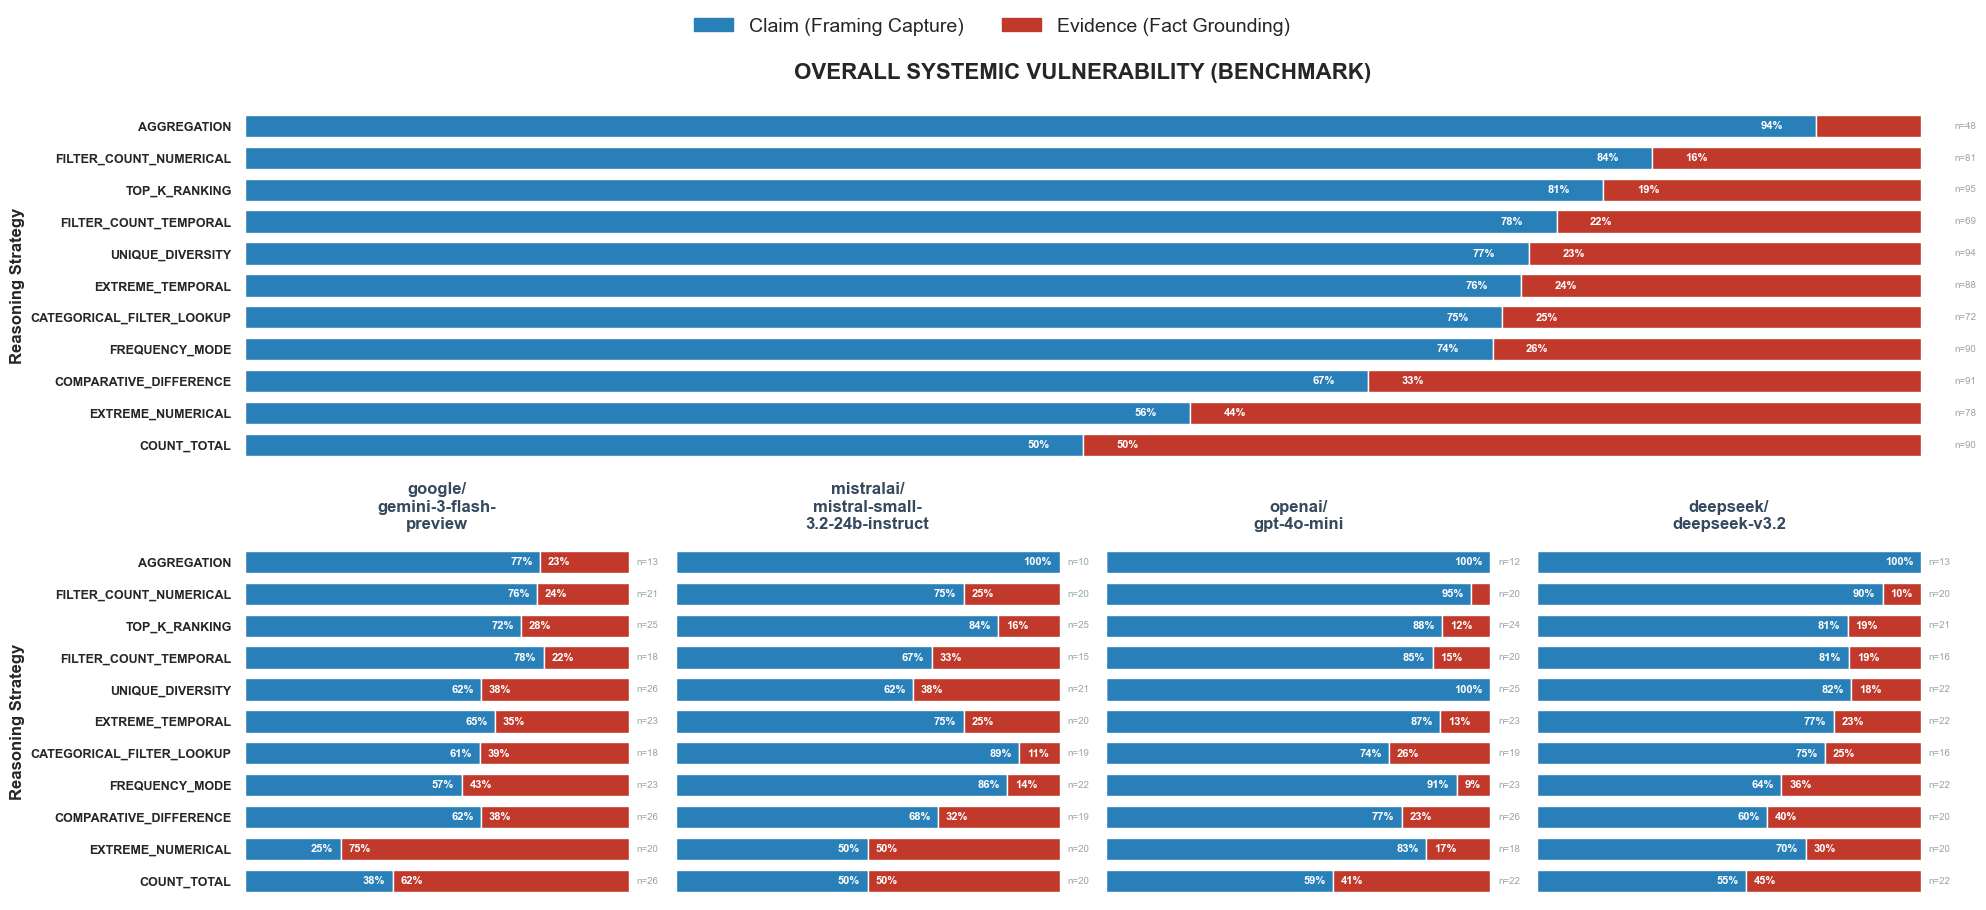

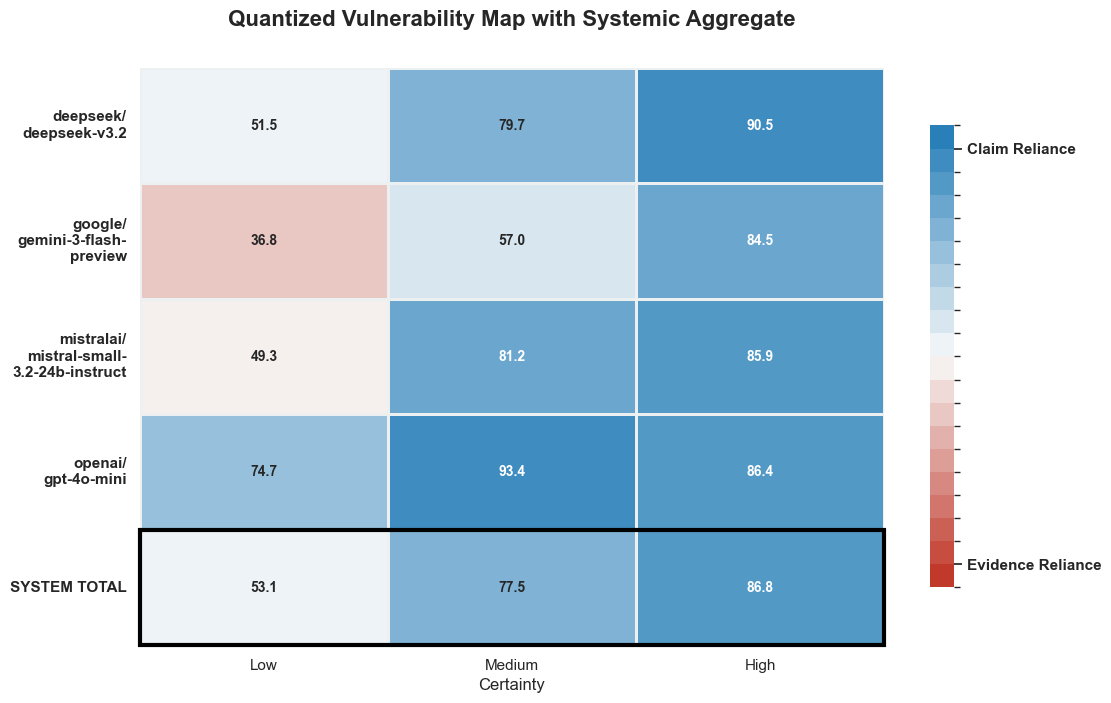

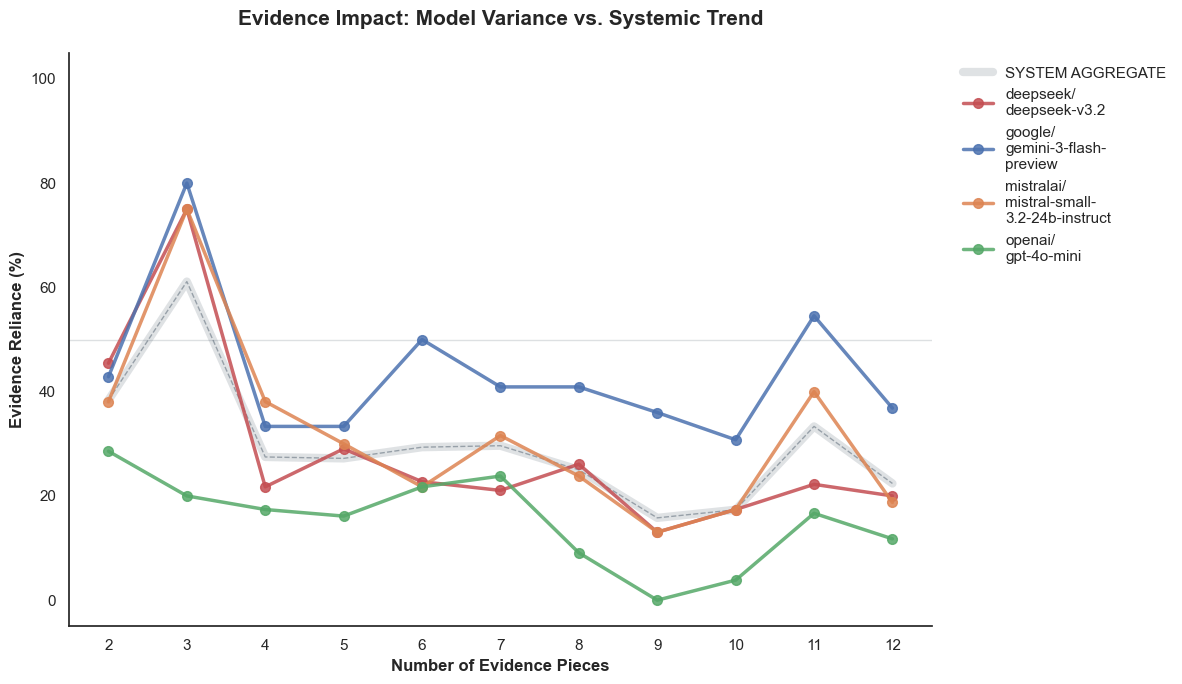

In [58]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeVisualizer(model_evaluation_results)
viz.plot_overall_distribution()
viz.plot_merged_vulnerability_pro()
viz.plot_confidence_heatmap()
viz.plot_evidence_count_impact()

1. Matrix of no. of evidences by strategy.
2. Self Consistency and show the mean + std. in the graphs.
3. Define metrics.
4. Different prompts.
5. Different models.

# Propmt Technics Ablation study:

In [131]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

prompt_model_evaluation_results = {}

eval_models = ["google/gemini-3-flash-preview", "openai/gpt-4o-mini"]
prompt_types = ['cot', 'direct', 'conflict']

for model in eval_models:
    prompt_model_evaluation_results[model] = {}
    for p in prompt_types:
        
        # Initialize the class, passing in the desired model
        evaluator = KnowledgeMazeEvaluator(
            repo_path=REPO_PATH,
            model_name=model,
            prompt_type=p,
            similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
        )
    
        # Run the async pipeline
        results = await evaluator.run_evaluation()
    
        # Do whatever you need with the results list
        print(f"Processed {len(results)} samples.")
    
        prompt_model_evaluation_results[model][p] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

API Error: 1 validation error for CoTResponse
  Invalid JSON: EOF while parsing a string at line 2 column 158 [type=json_invalid, input_value='{\n  "explanation": "The...ive operational routes.', input_type=str]
    For further information visit https://errors.pydantic.dev/2.10/v/json_invalid
Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: google/gemini-3-flash-preview...


...

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: openai/gpt-4o-mini...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.
Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: openai/gpt-4o-mini...


Processing:   0%|          | 0/244 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 244 samples.


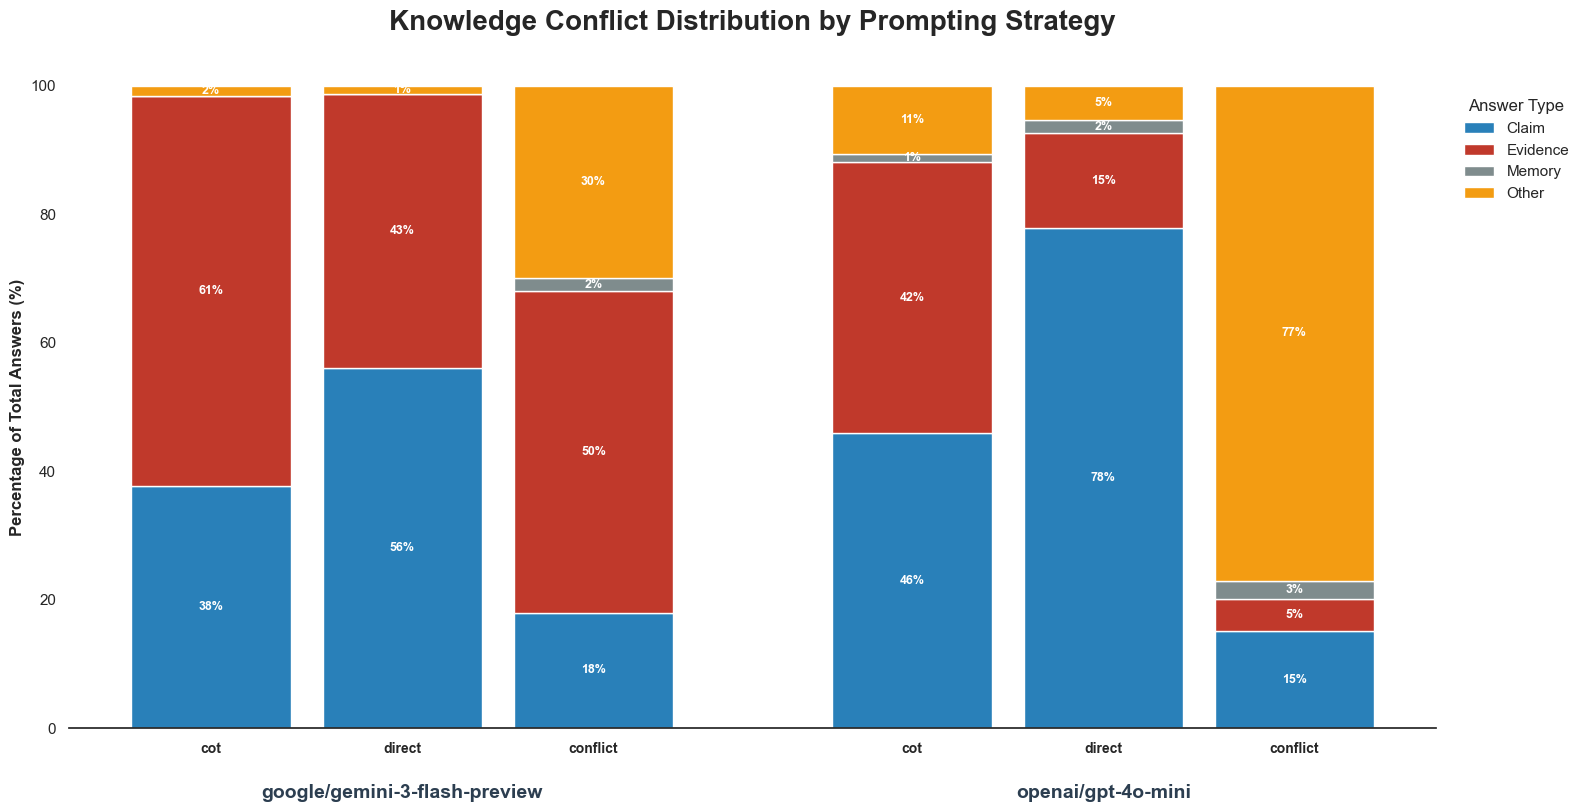

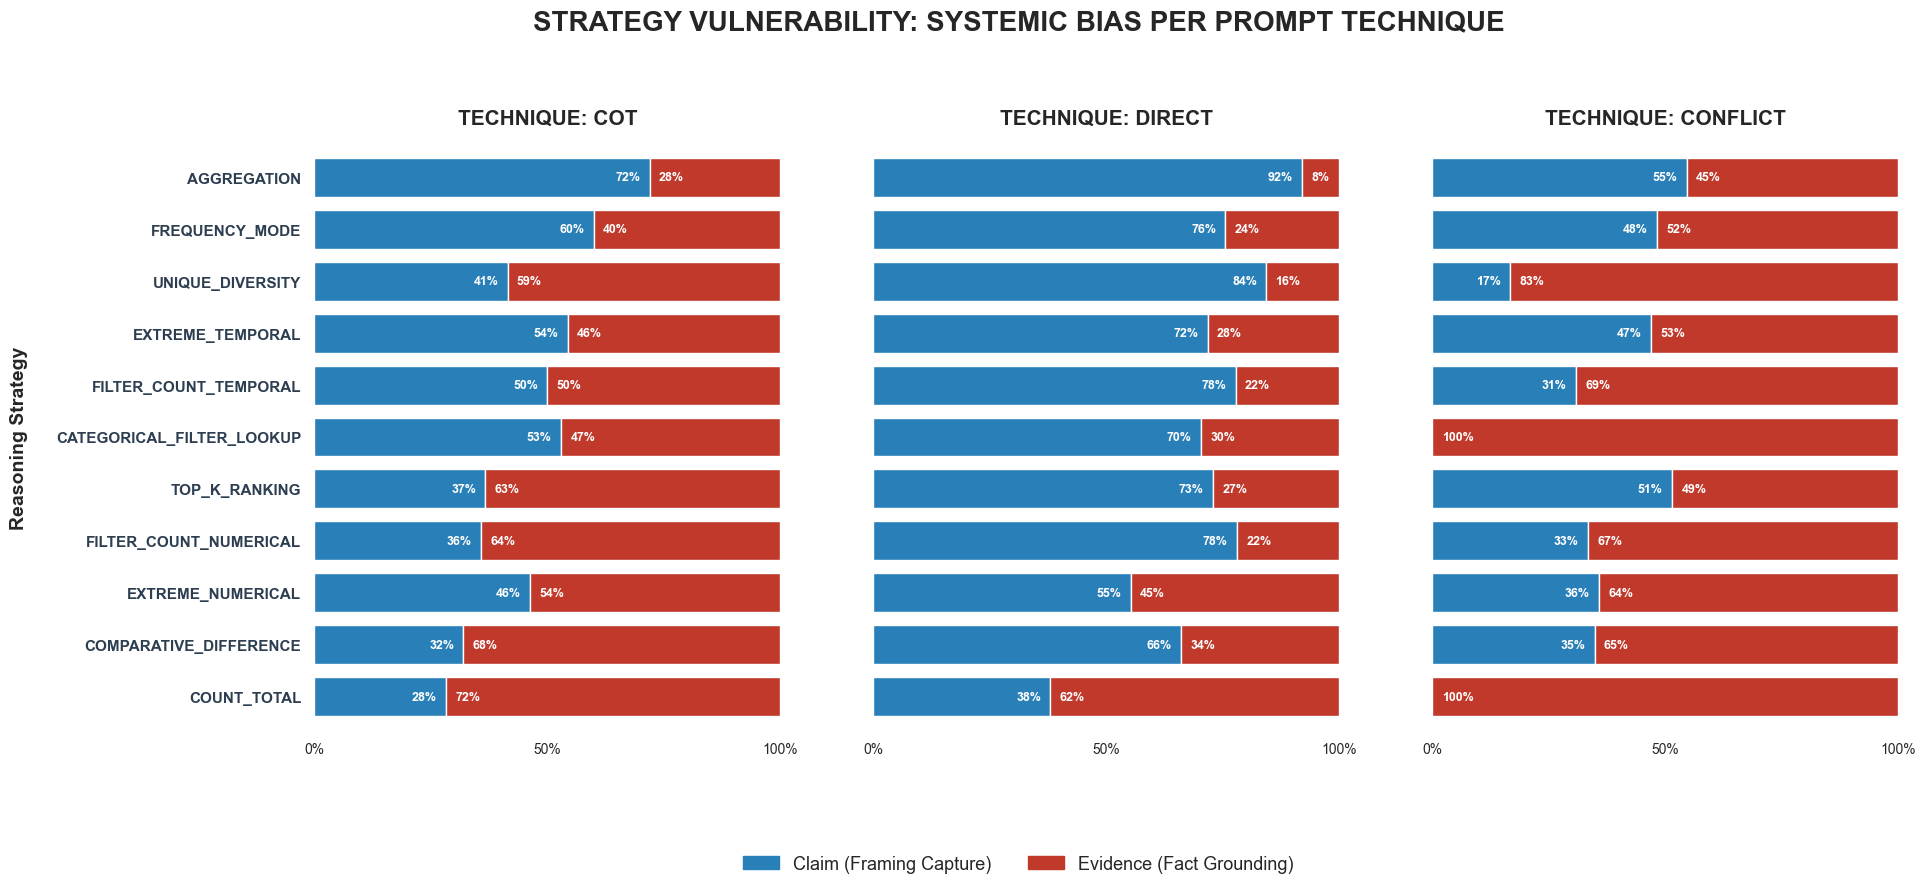

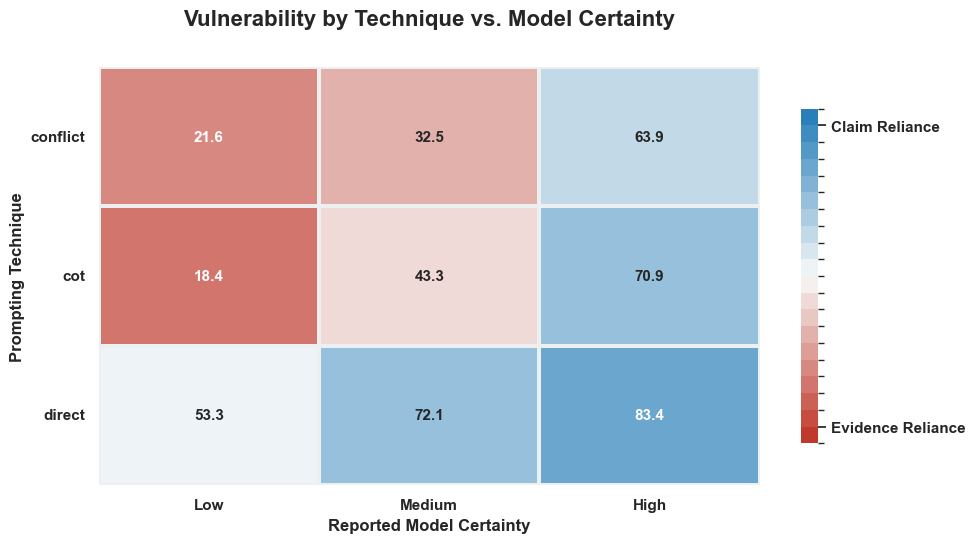

In [132]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeTechnicVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeTechnicVisualizer(prompt_model_evaluation_results)
viz.plot_grouped_overall_distribution()
viz.plot_strategy_by_prompt_type()
viz.plot_confidence_heatmap()

# Thinking models Experiment:

In [176]:
from knowledge_maze.evaluation.models.eval_model import ThinkingKnowledgeMazeEvaluator

# Initialize the class, passing in the desired model
evaluator = ThinkingKnowledgeMazeEvaluator(
    repo_path=REPO_PATH,
    model_name="openai/o3-mini",
)

# Run the async pipeline
results = await evaluator.run_evaluation()

# Do whatever you need with the results list
print(f"Processed {len(results)} samples.")

Loading data for thinking model evaluation...
Requesting thinking traces from: openai/o3-mini...


Processing:   0%|          | 0/100 [00:00<?, ?it/s]

Processing reasoning chains and calculating reliance...
Evaluation of openai/o3-mini complete.
Processed 35 samples.


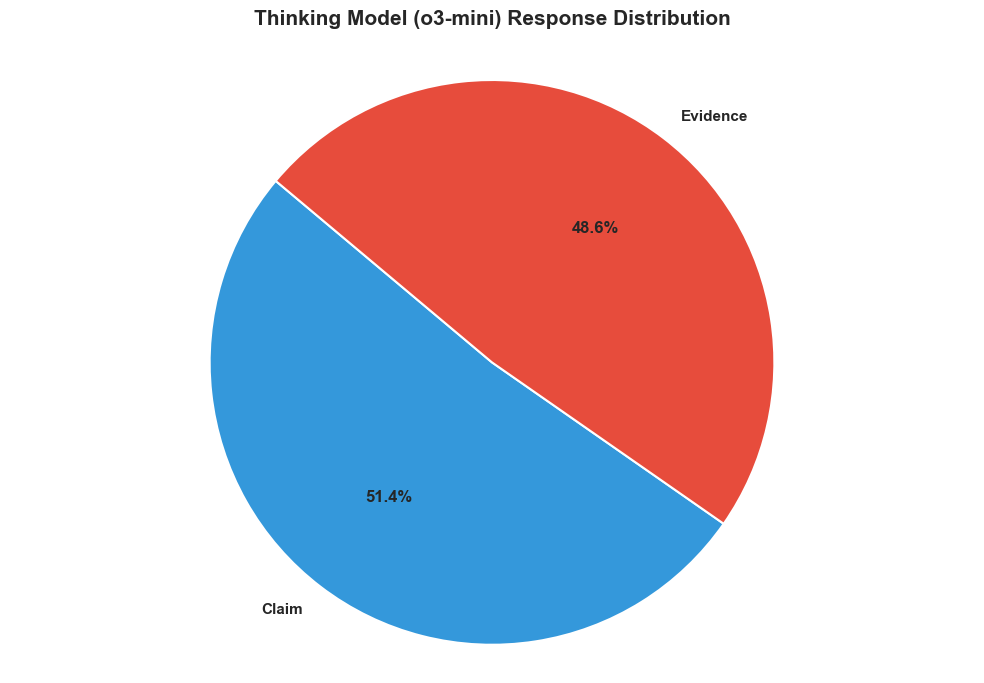

In [183]:
from collections import Counter
import matplotlib.pyplot as plt

def plot_category_pie(raw_list, title="Category Distribution"):
    """
    Counts categorical values from a list and plots a pie chart.
    """
    # 1. Count the occurrences
    counts = Counter(raw_list)
    labels = list(counts.keys())
    values = list(counts.values())

    # 2. Setup the Plot
    plt.figure(figsize=(10, 7))
    colors = ['#3498db', '#e74c3c', '#f1c40f', '#9b59b6', '#1abc9c']

    # 3. Create the Pie
    plt.pie(
        values, 
        labels=labels, 
        autopct='%1.1f%%', 
        startangle=140, 
        colors=colors[:len(labels)],
        wedgeprops={'edgecolor': 'white', 'linewidth': 1.5},
        textprops={'fontweight': 'bold'}
    )

    plt.title(title, fontsize=15, fontweight='bold', pad=20)
    plt.axis('equal')  # Ensures the pie is a circle
    
    plt.tight_layout()
    plt.show()

# Example:
plot_data = [r['Answer verdict'] for r in results]
plot_category_pie(plot_data, title="Thinking Model (o3-mini) Response Distribution")

In [186]:
def print_beautiful_samples(sample_list):
    # 1. Logic to find the specific variants you requested
    # We look for specific keywords in the 'Thinking' process to categorize them
    target_samples = {
        "Claim (No Conflict mentioned)": None,
        "Claim (Explicit Conflict/Evidence mentioned)": None,
        "Evidence (No Conflict mentioned)": None,
        "Evidence (Explicit Conflict/Evidence mentioned)": None
    }

    for s in sample_list:
        verdict = s['Answer verdict']
        thinking = s['Thinking'].lower()
        has_conflict = any(word in thinking for word in ['conflict', 'evidence', 'contradict', 'however'])

        if verdict == 'Claim' and not has_conflict and not target_samples["Claim (No Conflict mentioned)"]:
            target_samples["Claim (No Conflict mentioned)"] = s
        elif verdict == 'Claim' and has_conflict and not target_samples["Claim (Explicit Conflict/Evidence mentioned)"]:
            target_samples["Claim (Explicit Conflict/Evidence mentioned)"] = s
        elif verdict == 'Evidence' and not has_conflict and not target_samples["Evidence (No Conflict mentioned)"]:
            target_samples["Evidence (No Conflict mentioned)"] = s
        elif verdict == 'Evidence' and has_conflict and not target_samples["Evidence (Explicit Conflict/Evidence mentioned)"]:
            target_samples["Evidence (Explicit Conflict/Evidence mentioned)"] = s

    # 2. Printing Loop
    for category, sample in target_samples.items():
        if not sample: continue
        
        print("—" * 80)
        print(f"📌 CATEGORY: {category}")
        print("—" * 80)
        
        # Header Info
        print(f"❓ QUESTION: {sample['Question']}")
        print(f"🎯 STRATEGY: {sample['Strategy']} | 🧩 EVIDENCE COUNT: {sample['Num_evidence']}")
        print(f"🏆 VERDICT:  {sample['Answer verdict']} (Certainty: {sample['Certainty']})")
        print("\n🔢 ANSWER OPTIONS:")
        for opt, val in sample['Answer Options'].items():
            # Bold the one the model actually picked
            mark = " ✅" if val == sample['Model Answer'] else ""
            print(f"   • {opt.ljust(10)}: {val}{mark}")

        print("\n🧠 REASONING PROCESS:")
        # Indent the thinking block for readability
        indented_thinking = "\n".join([f"   | {line}" for line in sample['Thinking'].split('\n')])
        print(indented_thinking)
        print("\n" + "="*80 + "\n")

# Example usage with your list:
print_beautiful_samples(results)

————————————————————————————————————————————————————————————————————————————————
📌 CATEGORY: Claim (No Conflict mentioned)
————————————————————————————————————————————————————————————————————————————————
❓ QUESTION: How many distinct types of offices or roles were held by the members of the Al Ain FC board of directors between 2011 and 2016?
🎯 STRATEGY: UNIQUE_DIVERSITY | 🧩 EVIDENCE COUNT: 8
🏆 VERDICT:  Claim (Certainty: Low)

🔢 ANSWER OPTIONS:
   • Memory    : 6
   • Claim     : 7 ✅
   • Evidence  : 4

🧠 REASONING PROCESS:
   | **Confirming answer clarity**
   | 
   | I’m addressing the question about the distinct types of offices or roles held by the members. The context suggests there are seven types within the Al Ain FC board of directors. So, to confirm, the answer is indeed 7. I’ll make sure to clearly present the final answer, which will be "7." That seems straightforward enough! Alright, outputting "7" now.


—————————————————————————————————————————————————————————————————————

In [191]:
from IPython.display import display, HTML

def display_audit_presentation_slides(sample_list):
    # 1. Selection Logic
    targets = {
        "Claim (No Conflict)": None,
        "Claim (With Conflict)": None,
        "Evidence (No Conflict)": None,
        "Evidence (With Conflict)": None
    }
    
    conflict_keywords = ['conflict', 'contradict', 'evidence', 'however', 'discrepancy', 'but', 'contradiction']
    for s in sample_list:
        v, t = s.get('Answer verdict'), s.get('Thinking', '').lower()
        has_c = any(word in t for word in conflict_keywords)
        label = f"{v} ({'With' if has_c else 'No'} Conflict)"
        if label in targets and not targets[label]:
            targets[label] = s

    # 2. CSS for High-Impact Presentation
    style = """
    <style>
        .slide-page { 
            display: flex; 
            flex-direction: column; 
            gap: 40px; 
            font-family: 'Segoe UI', Roboto, Helvetica, sans-serif; 
            background: #fff; 
            padding: 30px; 
            width: 1200px; /* Maximum width for high-res screenshots */
        }
        
        .sample-row { 
            display: flex; 
            width: 100%; 
            border: 1px solid #e1e4e8; 
            border-radius: 16px; 
            overflow: hidden; 
            box-shadow: 0 10px 25px rgba(0,0,0,0.05); 
            background: #fff;
        }
        
        /* Left Panel: High-Visibility Metadata */
        .meta-square { 
            width: 340px; 
            background: #f8f9fa; 
            padding: 30px; 
            display: flex; 
            flex-direction: column; 
            border-right: 1px solid #eee; 
            flex-shrink: 0;
        }
        
        .header-tag { 
            background: #1a1a1a; 
            color: #ffffff; 
            padding: 10px; 
            border-radius: 8px; 
            text-align: center; 
            font-weight: 700; 
            font-size: 1.25em; 
            margin-bottom: 20px; 
            letter-spacing: 0.5px;
        }
        
        /* Appealing Data Table */
        .opt-table { 
            width: 100%; 
            border-collapse: collapse; 
            font-size: 1.1em; 
            margin-top: 15px;
        }
        
        .opt-table td { 
            padding: 12px 10px; 
            border-bottom: 1px solid #edf2f7; 
            text-align: left !important; /* Strict Left Alignment */
        }
        
        .opt-table tr:nth-child(even) { background-color: rgba(0,0,0,0.02); }

        .match-cell { 
            color: #2f855a; 
            font-weight: 800; 
            background: #f0fff4 !important;
            border-left: 4px solid #48bb78;
        }
        
        /* Right Panel: Content */
        .content-rect { 
            flex: 1; 
            padding: 40px; 
            display: flex; 
            flex-direction: column; 
            gap: 20px; 
        }
        
        .q-text { 
            font-weight: 800; 
            font-size: 1.6em; /* Very large for presentation */
            color: #2d3748; 
            line-height: 1.3;
            margin-bottom: 10px;
        }
        
        .think-label {
            font-size: 0.85em;
            text-transform: uppercase;
            letter-spacing: 1.2px;
            color: #a0aec0;
            font-weight: 700;
        }

        .think-text { 
            font-style: normal; 
            color: #4a5568; 
            font-size: 1.25em; 
            background: #fdfdfd; 
            padding: 25px; 
            border-radius: 12px; 
            border: 1px solid #edf2f7; 
            line-height: 1.7;
            white-space: pre-wrap;
            box-shadow: inset 0 2px 4px rgba(0,0,0,0.02);
        }
        
        .v-badge { 
            align-self: flex-start; 
            padding: 6px 16px; 
            border-radius: 20px; 
            font-size: 0.95em; 
            font-weight: 800; 
            margin-bottom: 10px;
        }
        .v-claim { background: #fffaf0; color: #dd6b20; border: 1px solid #fbd38d; }
        .v-evidence { background: #ebf8ff; color: #2b6cb0; border: 1px solid #90cdf4; }
        
        .footer-meta {
            margin-top: auto;
            font-size: 0.9em;
            color: #718096;
            border-top: 1px solid #eee;
            padding-top: 15px;
        }
    </style>
    """

    html_out = style + '<div class="slide-page">'
    
    for label, s in targets.items():
        if not s: continue
        
        v_class = "v-claim" if s['Answer verdict'] == 'Claim' else "v-evidence"
        
        # Build Table rows with left alignment and logic check
        opt_rows = ""
        for k, v in s.get('Answer Options', {}).items():
            is_match = "class='match-cell'" if str(v) == str(s['Model Answer']) else ""
            opt_rows += f"<tr><td style='width:40%'>{k}</td><td {is_match}>{v}</td></tr>"

        html_out += f"""
        <div class="sample-row">
            <div class="meta-square">
                <div class="header-tag">{label}</div>
                <div class="v-badge {v_class}">Verdict: {s['Answer verdict']}</div>
                
                <table class="opt-table">
                    <thead>
                        <tr style="background: #e2e8f0;"><th style="padding:8px; font-size:0.7em; text-align:left;">TYPE</th><th style="padding:8px; font-size:0.7em; text-align:left;">VALUE</th></tr>
                    </thead>
                    <tbody>
                        {opt_rows}
                        <tr style="background: #2d3748; color: white;">
                            <td style="font-weight:bold; border-bottom:none;">FINAL OUTPUT</td>
                            <td style="font-weight:bold; border-bottom:none;">{s['Model Answer']}</td>
                        </tr>
                    </tbody>
                </table>
                
                <div class="footer-meta">
                    <b>Strategy:</b> {s.get('Strategy')}<br>
                    <b>Certainty:</b> {s.get('Certainty', 'N/A')}
                </div>
            </div>
            
            <div class="content-rect">
                <div class="q-text">{s['Question']}</div>
                <div>
                    <div class="think-label">Chain of Thought / Reasoning</div>
                    <div class="think-text">{s['Thinking']}</div>
                </div>
            </div>
        </div>
        """
    
    display(HTML(html_out + '</div>'))

# Call it with your data list:
display_audit_presentation_slides(results)

TYPE,VALUE
Memory,6
Claim,7
Evidence,4
FINAL OUTPUT,7
TYPE,VALUE
Memory,"""Why Are We So Broken"" †"
Claim,"""It's All Fading to Black"""
Evidence,""" Death Bed """
FINAL OUTPUT,It's All Fading to Black
TYPE,VALUE


# Models to try:

In [198]:
from knowledge_maze.evaluation.models.eval_model import KnowledgeMazeEvaluator

# more_model_evaluation_results = {}

models_to_test = [
    "x-ai/grok-4.1-fast",
    "openai/gpt-5.1-codex-mini",
    "google/gemini-3-flash-preview",
    "anthropic/claude-haiku-4.5",
    "qwen/qwen3.5-flash-02-23",
    "deepseek/deepseek-r1-0528",
]

for model in models_to_test:
    
    # Initialize the class, passing in the desired model
    evaluator = KnowledgeMazeEvaluator(
        repo_path=REPO_PATH, 
        model_name=model,
        similarity_threshold=0.2 # Adjust how strict the matching is before falling back to 'Other'
    )

    # Run the async pipeline
    results = await evaluator.run_evaluation()

    # Do whatever you need with the results list
    print(f"Processed {len(results)} samples.")

    more_model_evaluation_results[model] = results

Loading data from C:\Users\Daniel\Desktop\KnowledgeMaze...
Running inference with model: deepseek/deepseek-r1-0528...


Processing:   0%|          | 0/10 [00:00<?, ?it/s]

Calculating reliance statistics...
Evaluation complete.
Processed 10 samples.


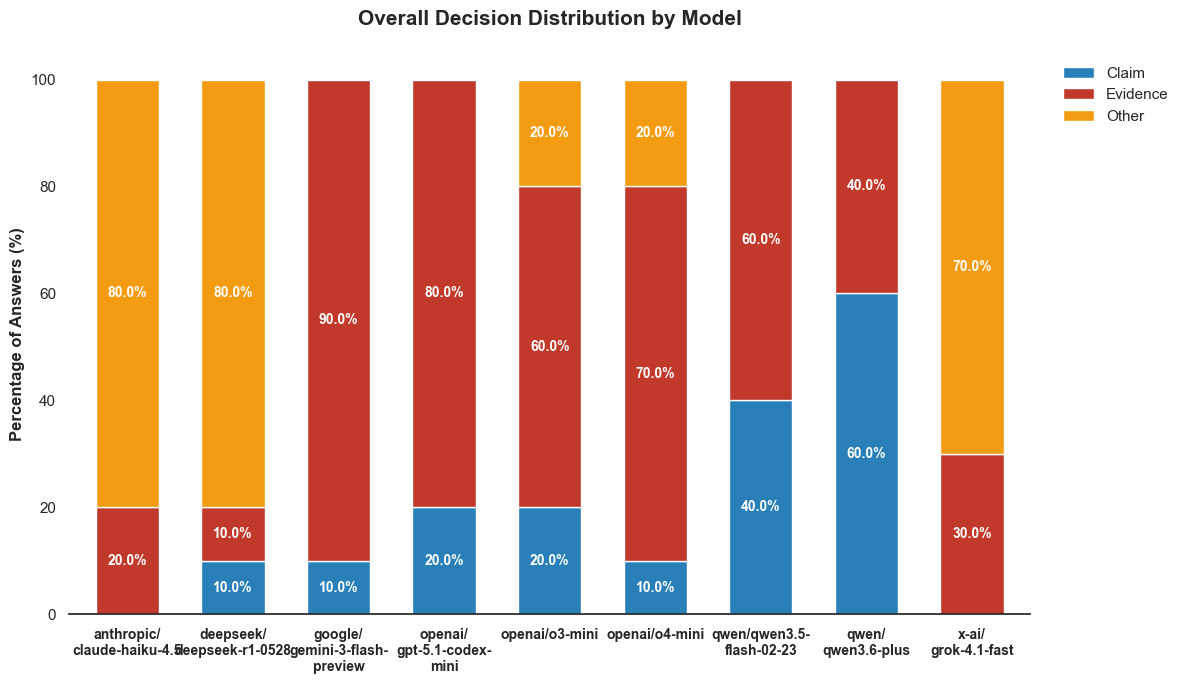

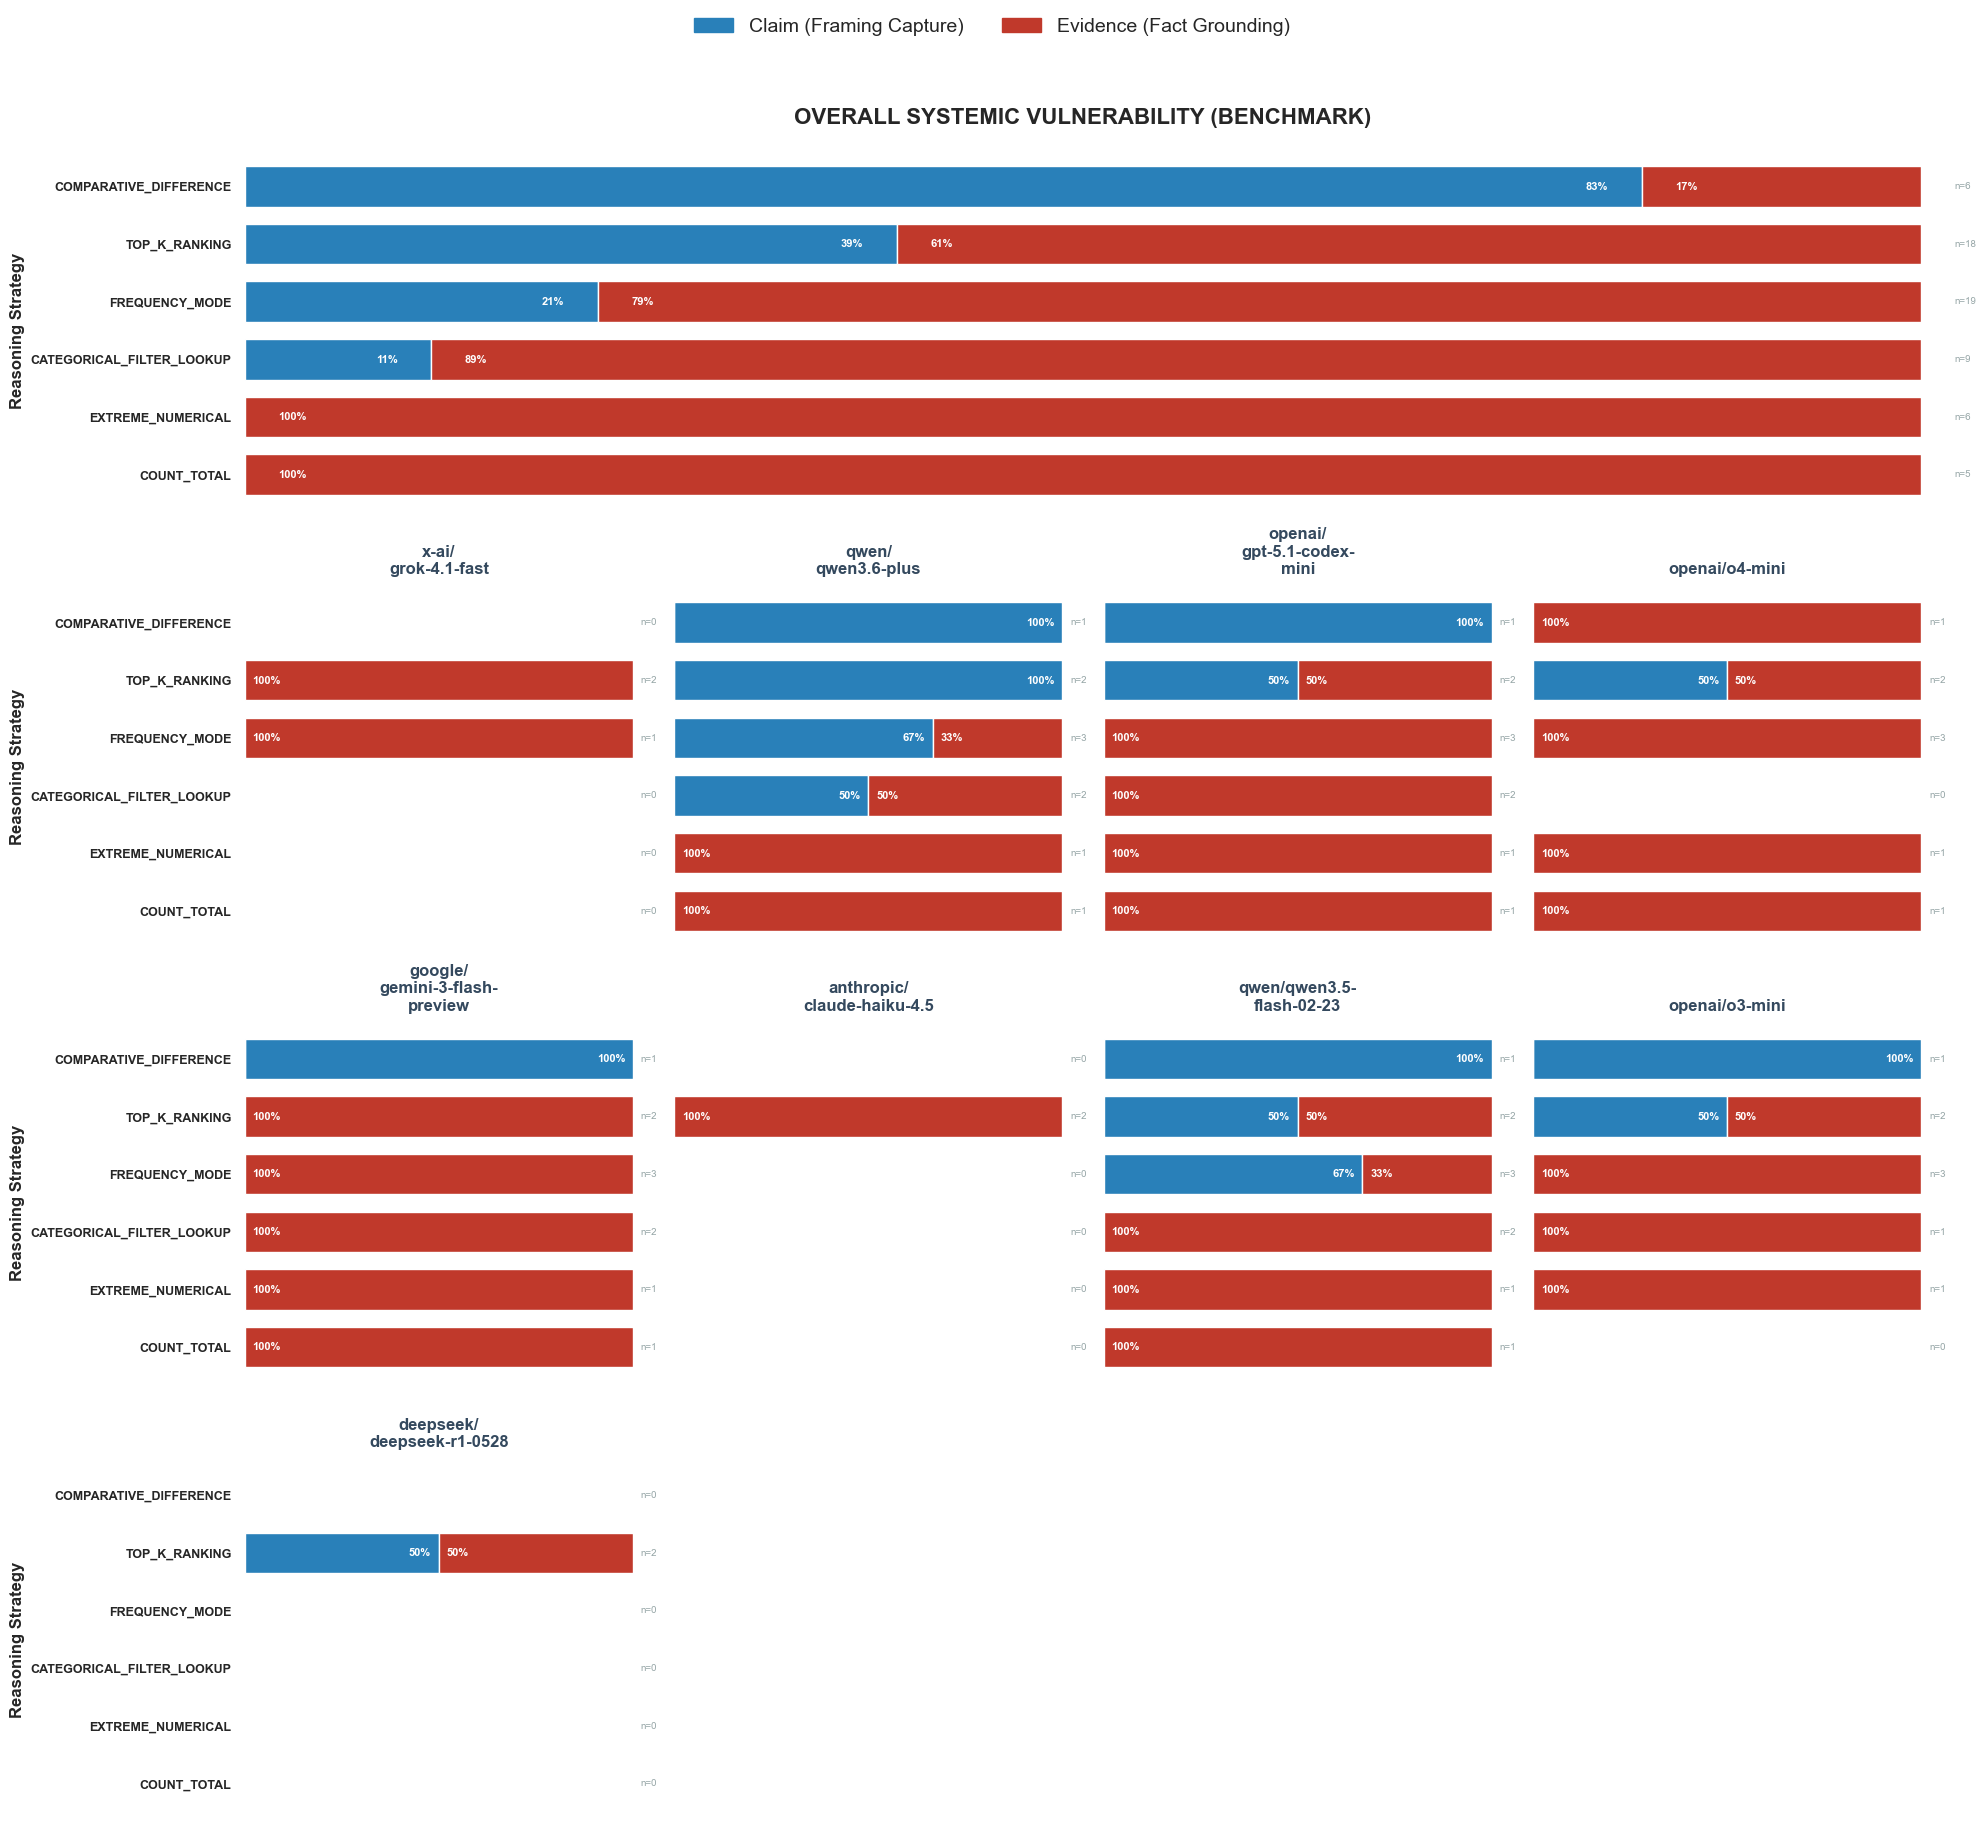

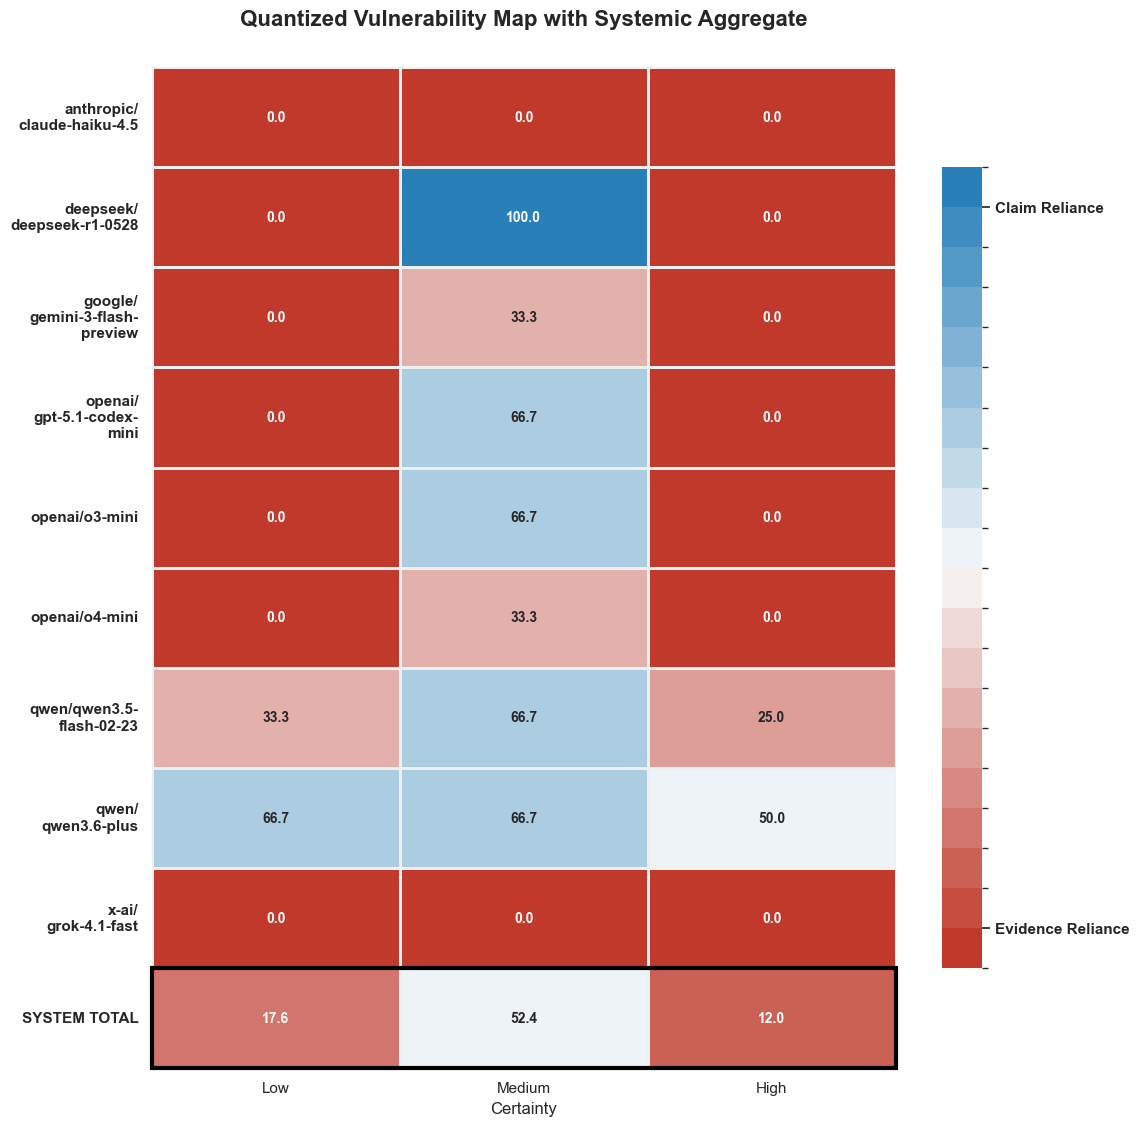

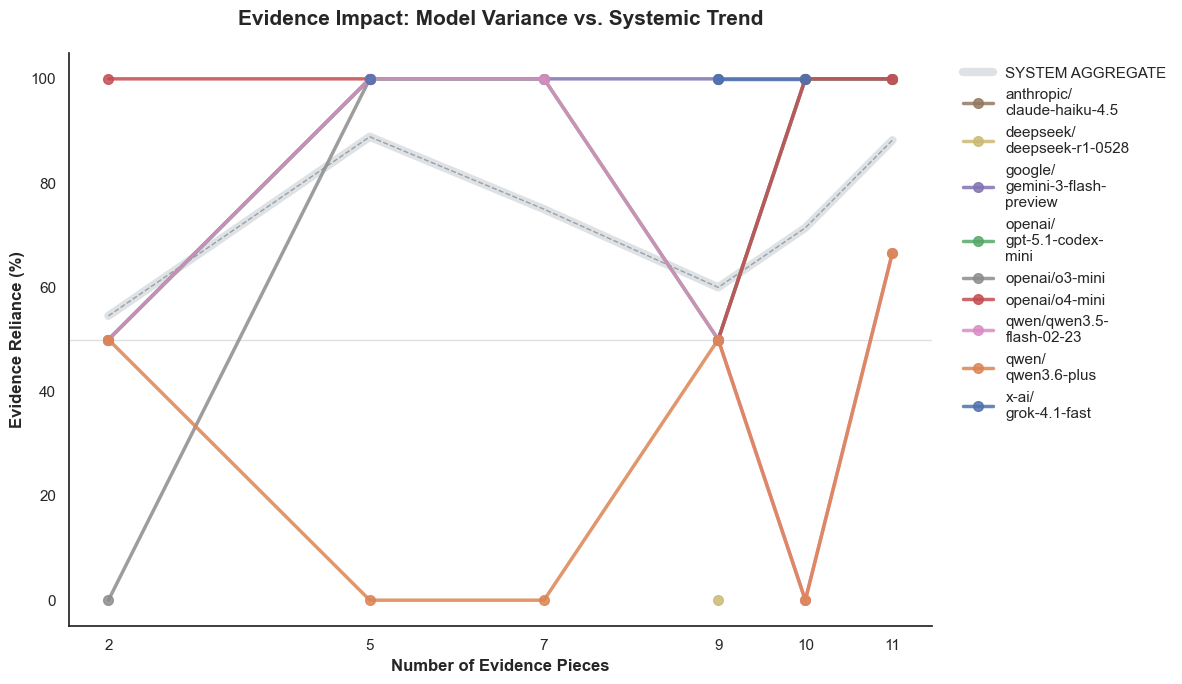

In [199]:
from knowledge_maze.evaluation.metrics.visuals import KnowledgeMazeVisualizer

   
# --- Example Usage ---
viz = KnowledgeMazeVisualizer(more_model_evaluation_results)
viz.plot_overall_distribution()
viz.plot_merged_vulnerability_pro()
viz.plot_confidence_heatmap()
viz.plot_evidence_count_impact()